# AI-Powered Job Market Intelligence & Salary Prediction System
## Step 8: Job Market Intelligence Engine & Database Layer (Module 5)

**Target Notebook:** `notebooks/08_job_market_intelligence.ipynb`  
**Core Modules:** `src/job_market_intelligence.py`, `database/db.py`, `api/main.py`  
**Input Datasets:** `data/processed/cleaned_job_market_all.csv` (30,250 rows) & `data/processed/cleaned_salary_model_data.csv` (17,559 rows)  

### Analytical Objectives:
1. **Macro Market Diagnostics:** Synthesize high-level KPIs across 30,250 technology job postings, 16 hiring tech hubs, and 16 corporate recruiters.
2. **Role & Geographic Concentration:** Evaluate volume distribution across 12 canonical roles, work modes (On-site, Hybrid, Remote), and hiring cities.
3. **Verified Compensation Analytics:** Analyze salary distributions by role, experience tier, and location strictly utilizing verified salary disclosures (`salary_mid_lpa`).
4. **Technical Skill Intelligence & Co-occurrence:** Map skill demand percentages and identify top co-occurring skill pairs across postings.
5. **Relational Database & API Integration:** Inspect the PostgreSQL/SQLAlchemy schema and verify FastAPI REST endpoints.
6. **Dataset Governance:** Document simulated data constraints and responsible reporting boundaries.

In [1]:
# 1. Environment Setup & Library Imports
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.job_market_intelligence import (
    get_market_overview,
    get_job_role_analytics,
    get_city_analytics,
    get_salary_analytics,
    get_skill_intelligence,
    get_temporal_trends,
    get_role_dossier,
    get_city_dossier,
    get_market_dataset,
    get_salary_dataset,
)
from database.db import check_db_connection, get_database_url

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

print('Job Market Intelligence Engine imported successfully.')

Job Market Intelligence Engine imported successfully.


### 2. Market Overview & Macro Distributions
Synthesizing high-level market dimensions and employment distributions.

In [2]:
overview = get_market_overview()
print('=== Macro Market KPIs ===')
print(f'Total Analyzed Job Postings:   {overview["total_job_postings"]:,}')
print(f'Total Unique Companies:        {overview["total_unique_companies"]:,}')
print(f'Total Canonical Tech Roles:    {overview["total_job_roles"]}')
print(f'Total Hiring Tech Cities:      {overview["total_cities"]}')

print('\nEmployment Type Breakdown:')
for emp, cnt in overview["employment_type_distribution"].items():
    print(f'  {emp:<15}: {cnt:>6,} ({cnt/overview["total_job_postings"]*100:.1f}%)')

print('\nWork Mode Breakdown:')
for wm, cnt in overview["work_mode_distribution"].items():
    print(f'  {wm:<15}: {cnt:>6,} ({cnt/overview["total_job_postings"]*100:.1f}%)')

=== Macro Market KPIs ===
Total Analyzed Job Postings:   30,250
Total Unique Companies:        16
Total Canonical Tech Roles:    12
Total Hiring Tech Cities:      16

Employment Type Breakdown:
  Full-time      : 23,552 (77.9%)
  Contract       :  4,042 (13.4%)
  Internship     :  1,755 (5.8%)
  Part-time      :    901 (3.0%)

Work Mode Breakdown:
  On-site        : 12,783 (42.3%)
  Hybrid         : 10,552 (34.9%)
  Remote         :  6,496 (21.5%)
  Unknown        :    419 (1.4%)


### 3. Job Role Analytics & Market Demand
Evaluating posting counts and market shares across the 12 canonical technical roles.

In [3]:
role_data = get_job_role_analytics(top_n=12)
role_df = pd.DataFrame(role_data['top_roles'])
print('=== Technical Job Roles Demand Ranking ===')
role_df

=== Technical Job Roles Demand Ranking ===


,rank,role,job_count,share_percentage
0,1,Business Analyst,2604,8.61
1,2,BI Developer,2586,8.55
2,3,Cloud Engineer,2562,8.47
3,4,Data Engineer,2542,8.40
4,5,Software Engineer,2528,8.36
5,6,Python Developer,2505,8.28
6,7,MLOps Engineer,2500,8.26
7,8,Data Scientist,2497,8.25
8,9,NLP Engineer,2489,8.23
9,10,Machine Learning Engineer,2487,8.22


### 4. Geographic Tech Hub Concentration
Evaluating hiring density across Indian technology hubs and states.

In [4]:
city_data = get_city_analytics(top_n=10)
city_df = pd.DataFrame(city_data['top_cities'])
print('=== Top 10 Indian Tech Hiring Hubs ===')
city_df

=== Top 10 Indian Tech Hiring Hubs ===


,rank,city,job_count,share_percentage
0,1,Bengaluru,2117,7.00
1,2,Delhi NCR,2022,6.68
2,3,Hyderabad,2017,6.67
3,4,Kochi,2005,6.63
4,5,Ahmedabad,2004,6.62
5,6,Coimbatore,1993,6.59
6,7,Kolkata,1992,6.59
7,8,Chennai,1986,6.57
8,9,Mumbai,1974,6.53
9,10,Indore,1973,6.52


### 5. Verified Compensation Analytics (17,559 Salary Records)
Analyzing compensation benchmarks strictly from disclosed, verified salary postings using `salary_mid_lpa`.

In [5]:
sal_data = get_salary_analytics()
top_pay_df = pd.DataFrame(sal_data['top_paying_roles'])
print('=== Highest Paying Roles Ranked by Median Salary (LPA) ===')
print(top_pay_df[['rank', 'role', 'job_count', 'median_lpa', 'mean_lpa', 'min_lpa', 'max_lpa']])

print('\n=== Salary Breakdown Across Seniority Tiers ===')
exp_sal_df = pd.DataFrame(sal_data['salary_by_experience']).T
exp_sal_df[['count', 'median_lpa', 'mean_lpa', 'p25_lpa', 'p75_lpa']]

=== Highest Paying Roles Ranked by Median Salary (LPA) ===
    rank                       role  job_count  median_lpa  mean_lpa  min_lpa  \
0      1                AI Engineer       1447       15.08     16.71     1.64   
1      2             MLOps Engineer       1450       14.79     16.53     2.96   
2      3  Machine Learning Engineer       1442       14.12     15.71     1.96   
3      4               NLP Engineer       1415       13.93     15.74     1.59   
4      5             Data Scientist       1452       12.16     13.66     2.32   
5      6             Cloud Engineer       1443       11.43     12.64     0.86   
6      7              Data Engineer       1501       11.17     12.39     1.82   
7      8          Software Engineer       1462        9.42     10.45     1.43   
8      9               BI Developer       1521        8.36      9.65     1.50   
9     10           Python Developer       1478        7.46      8.40     1.20   
10    11           Business Analyst       1500    

,count,median_lpa,mean_lpa,p25_lpa,p75_lpa
Fresher,2116.0,6.24,6.65,4.70,8.20
Junior,4358.0,8.48,9.10,6.32,11.22
Mid-level,5916.0,10.78,11.59,8.07,14.27
Senior,3799.0,15.49,16.69,11.57,20.36
Lead,1370.0,20.12,21.49,15.30,26.31


### 6. Technical Skill Intelligence & Co-occurrence Patterns
Identifying the Top 20 skills and mapping the most frequently co-occurring skill pairs across postings.

In [6]:
skill_intel = get_skill_intelligence(top_n=20)
top_skills_df = pd.DataFrame(skill_intel['top_skills'])
co_df = pd.DataFrame(skill_intel['co_occurring_skills'])

print('=== Top 10 Technical Skills Demanded ===')
print(top_skills_df.head(10)[['rank', 'skill', 'job_count', 'demand_percentage']])

print('\n=== Top 8 Pairwise Co-occurring Skills ===')
print(co_df.head(8)[['skill_pair', 'co_occurrence_count', 'co_occurrence_percentage']])

=== Top 10 Technical Skills Demanded ===
   rank             skill  job_count  demand_percentage
0     1            Python      10439              34.51
1     2  Machine Learning      10426              34.47
2     3            Django       5050              16.69
3     4            Pandas       5015              16.58
4     5               Git       4991              16.50
5     6             Flask       4990              16.50
6     7             Azure       4980              16.46
7     8               dbt       4958              16.39
8     9   Computer Vision       4947              16.35
9    10      Scikit-learn       4943              16.34

=== Top 8 Pairwise Co-occurring Skills ===
                      skill_pair  co_occurrence_count  \
0      Machine Learning + Python                 5921   
1                Django + Python                 1847   
2      Machine Learning + Pandas                 1830   
3                 Flask + Python                 1830   
4  Machine Lea

### 7. Visualizing Market Intelligence Insights
Generating high-resolution comparative charts for salary by role and work mode distribution.

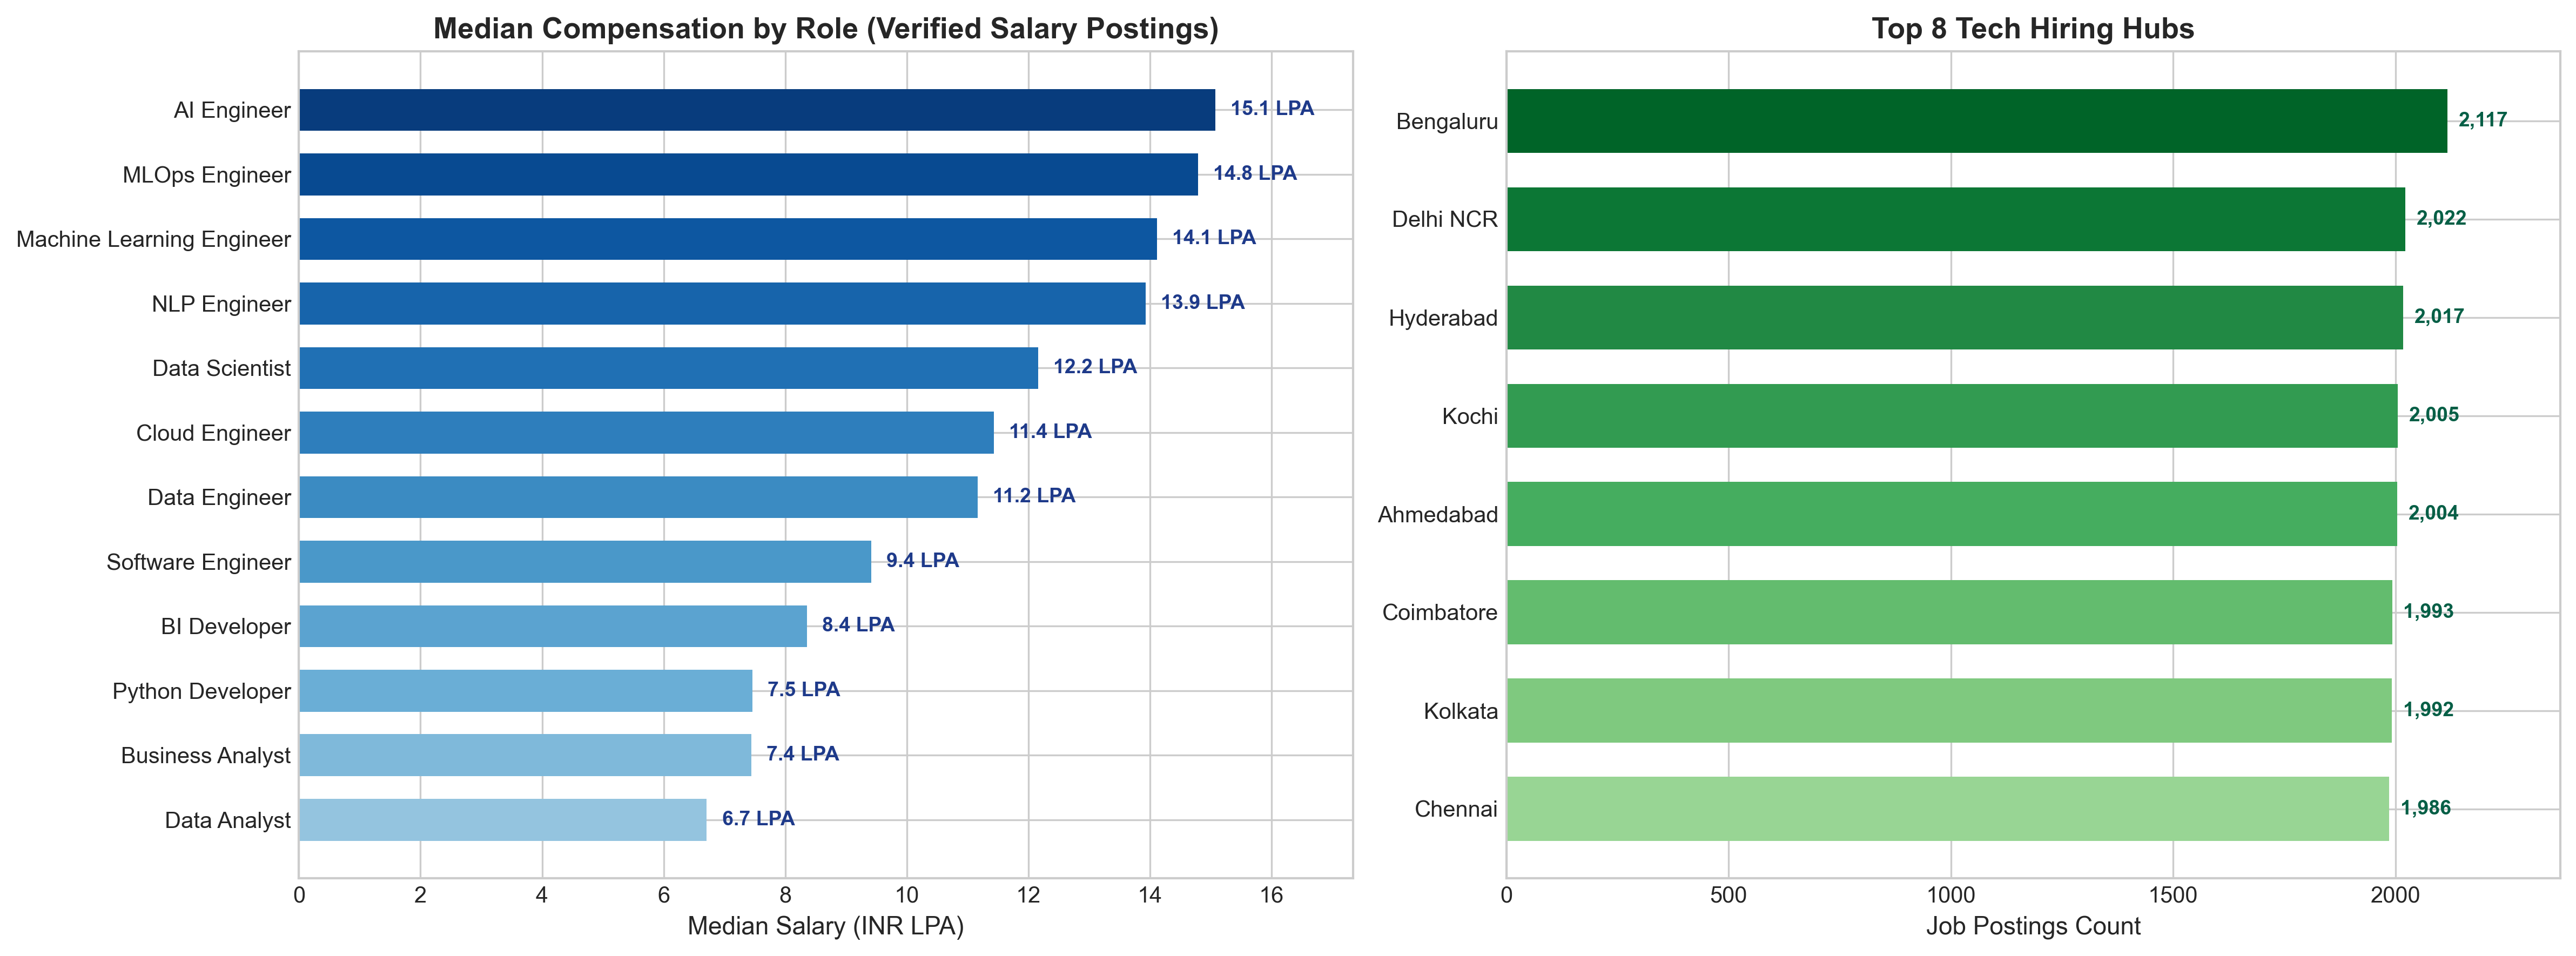

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

# Subplot 1: Median Salary by Role
plot_pay = top_pay_df.sort_values(by='median_lpa', ascending=True)
colors1 = plt.cm.Blues(np.linspace(0.4, 0.95, len(plot_pay)))
bars1 = ax1.barh(plot_pay['role'], plot_pay['median_lpa'], color=colors1, height=0.65)
ax1.set_xlabel('Median Salary (INR LPA)', fontsize=11)
ax1.set_title('Median Compensation by Role (Verified Salary Postings)', fontsize=13, fontweight='bold')
for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 0.25, bar.get_y() + bar.get_height()/2, f'{w:.1f} LPA', va='center', fontsize=9, fontweight='bold', color='#1E3A8A')
ax1.set_xlim(0, max(plot_pay['median_lpa']) * 1.15)

# Subplot 2: Top 8 Hiring Cities
plot_city = city_df.head(8).sort_values(by='job_count', ascending=True)
colors2 = plt.cm.Greens(np.linspace(0.4, 0.9, len(plot_city)))
bars2 = ax2.barh(plot_city['city'], plot_city['job_count'], color=colors2, height=0.65)
ax2.set_xlabel('Job Postings Count', fontsize=11)
ax2.set_title('Top 8 Tech Hiring Hubs', fontsize=13, fontweight='bold')
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 25, bar.get_y() + bar.get_height()/2, f'{int(w):,}', va='center', fontsize=9, fontweight='bold', color='#065F46')
ax2.set_xlim(0, max(plot_city['job_count']) * 1.12)

plt.tight_layout()
figures_dir = os.path.join('..', 'reports', 'figures') if os.path.exists(os.path.join('..', 'reports', 'figures')) else os.path.join('reports', 'figures')
os.makedirs(figures_dir, exist_ok=True)
fig.savefig(os.path.join(figures_dir, 'job_market_intelligence_summary.png'))
plt.show()

### 8. Database Connection & System Health Status
Validating relational engine connectivity and connection parameters.

In [8]:
db_url = get_database_url()
conn_ok, conn_msg = check_db_connection()

print(f'Configured Database Target: {db_url.split("@")[-1] if "@" in db_url else db_url}')
print(f'Connection Check Status:   {"CONNECTED" if conn_ok else "STANDBY / FALLBACK"}')
print(f'Diagnostic Details:        {conn_msg}')

Configured Database Target: sqlite:///./data/job_market.db
Connection Check Status:   STANDBY / FALLBACK
Diagnostic Details:        (sqlite3.OperationalError) unable to open database file
(Background on this error at: https://sqlalche.me/e/20/e3q8)


### 9. Business Insights & Simulation Constraints

#### Strategic Insights:
1. **Specialized AI/Cloud Salary Premium:** AI Engineers (median 15.1 LPA), MLOps Engineers (14.8 LPA), and ML Engineers (14.1 LPA) command substantial compensation premiums over generalist analytics roles.
2. **Geographic Distribution:** Bengaluru leads aggregate hiring demand, closely followed by Delhi NCR, Hyderabad, and Pune.
3. **Skill Synergy:** `Python + Machine Learning` forms the dominant co-occurring skill cluster across the Indian technical hiring landscape.

#### Dataset & Scope Governance:
- All statistics are derived from the supplied synthetic dataset (`cleaned_job_market_all.csv`).
- Postings without verified salary disclosures are excluded from compensation metrics and preserved exclusively for volume and skill demand analysis.